<a href="https://colab.research.google.com/github/Marques07/IPCA-Prophet-vs-XGBoost/blob/main/01_EDA_e_Extracao.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Prophet vs XGboost: Inflação central**

## Project Introduction


Importing the pandas library and creating a dictionary with the code of each selected database:

* IPCA — Broad Consumer Price Index (Brazil's official inflation index, calculated by IBGE)
* SELIC — Special System for Settlement and Custody (Brazil's benchmark interest rate, defined by the Central Bank every 45 days by the COPOM committee)
* Exchange Rate — USD/BRL rate (how many Brazilian reais equal one US dollar)
* IGP-M — General Market Price Index (measures price variation in wholesale, construction, and retail sectors. It tends to anticipate IPCA movements, since what rises in wholesale today reaches the end consumer later.)

After that, we apply a loop to fetch each database from the API using its corresponding code. The BCB API rejects requests without a browser identification header, so we include a header to identify ourselves and send a request to obtain a response. We then read that response as JSON and convert it into a DataFrame. Next, we set the date column to datetime format, and if any value column contains an error, it returns a null value instead of breaking the code. Finally, we rename each column with its proper name and print the number of records and the date range of the data.

In [1]:

import pandas as pd
import requests

codigos = {
    'ipca': 433,
    'selic': 4189,
    'cambio': 3698,
    'igpm': 189
}

dfs = {}
for nome, codigo in codigos.items():
    url = f'https://api.bcb.gov.br/dados/serie/bcdata.sgs.{codigo}/dados?formato=json'
    headers = {'User-Agent': 'Mozilla/5.0'}
    response = requests.get(url, headers=headers)
    df_temp = pd.DataFrame(response.json())
    df_temp['data'] = pd.to_datetime(df_temp['data'], format='%d/%m/%Y')
    df_temp['valor'] = pd.to_numeric(df_temp['valor'], errors='coerce')
    df_temp = df_temp.rename(columns={'valor': nome})
    dfs[nome] = df_temp

print("Series loaded:")
for nome, df in dfs.items():
    print(f"{nome}: {df.shape[0]} records | {df['data'].min().date()} até {df['data'].max().date()}")

Series loaded:
ipca: 561 records | 1980-01-01 até 2026-09-01
selic: 483 records | 1986-08-01 até 2026-10-01
cambio: 884 records | 1953-02-01 até 2026-09-01
igpm: 448 records | 1989-06-01 até 2026-09-01


In [2]:
for nome, df in dfs.items():
    print(f"\n{nome}:")
    print(df.tail())


ipca:
          data  ipca
556 2026-05-01  0.58
557 2026-06-01  0.16
558 2026-07-01  0.07
559 2026-08-01 -0.32
560 2026-09-01  0.82

selic:
          data  selic
478 2026-06-01  14.29
479 2026-07-01  14.15
480 2026-08-01  13.94
481 2026-09-01  13.78
482 2026-10-01  13.65

cambio:
          data  cambio
879 2026-05-01  4.9837
880 2026-06-01  5.1276
881 2026-07-01  5.1139
882 2026-08-01  5.1532
883 2026-09-01  5.1447

igpm:
          data  igpm
443 2026-05-01  0.84
444 2026-06-01 -0.50
445 2026-07-01 -1.16
446 2026-08-01 -0.22
447 2026-09-01  1.57


We create a necessary copy to ensure that the original DataFrame from the dfs
dictionary is not modified during subsequent transformations. We store this copy
in the df_master variable, then for each column whose name is in the selection,
we perform a merge using the date column as the reference key with the inner
method. As a result, we get a single DataFrame with all values connected by
matching dates.

In [3]:
df_master = dfs['ipca'].copy()

for nome in ['selic', 'cambio', 'igpm']:
    df_master = df_master.merge(dfs[nome], on='data', how='inner')

print(df_master.shape)
print(df_master.head())
print(df_master.tail())


(448, 5)
        data   ipca     selic  cambio   igpm
0 1989-06-01  28.65   1486.02   1.337  19.68
1 1989-07-01  27.74   3005.24   1.914  35.90
2 1989-08-01  33.71   2687.61   2.475  36.92
3 1989-09-01  37.56   6002.01   3.267  39.92
4 1989-10-01  39.77  10676.54   4.490  40.64
          data  ipca  selic  cambio  igpm
443 2026-05-01  0.58  14.40  4.9837  0.84
444 2026-06-01  0.16  14.29  5.1276 -0.50
445 2026-07-01  0.07  14.15  5.1139 -1.16
446 2026-08-01 -0.32  13.94  5.1532 -0.22
447 2026-09-01  0.82  13.78  5.1447  1.57


# **EDA**

* The dataset was filtered from January 2000 onwards. The hyperinflation period
prior to the Plano Real (1994) produced variations of a completely different
magnitude from the current monetary regime. Including data prior to 2000 would
introduce patterns incompatible with today's inflationary dynamics, compromising
the models' ability to generalize.

* Furthermore, reset_index(drop=True) is applied
after the filter so that the indices are restarted from zero. Without it, the
filtered DataFrame's indices would keep the original numbering, for example,
starting at 132 instead of 0, which can cause issues in subsequent operations
that assume sequential indices

In [4]:


df_master = df_master[df_master['data'] >= '2000-01-01'].reset_index(drop=True)
df_master.head()


,data,ipca,selic,cambio,igpm
0,2000-01-01,0.62,18.94,1.8037,1.24
1,2000-02-01,0.13,18.87,1.7753,0.35
2,2000-03-01,0.22,18.85,1.7420,0.15
3,2000-04-01,0.42,18.62,1.7682,0.23
4,2000-05-01,0.01,18.51,1.8279,0.31


In [7]:
# Plotting

import plotly.express as px
def plotting(title, data, x, y, x_label, y_label ):
    fig = px.line(data, x=df_master[x], y=df_master[y], labels={x: x_label, y: y_label})

    fig.update_layout(template='simple_white', font=dict(size=18), title_text = title, width=650, title_x = 0.5, height = 400)

    fig.show()

plotting('IPCA Evolution (2000-2025)', df_master, 'data', 'ipca', 'Date', 'Values')






In [11]:

ipca = df_master['ipca']

print(f"Total de linhas esperadas: 321")
print(f"Total real: {len(ipca)}")
print(f"Nulos: {ipca.isna().sum()}")
print(f"Negativos (deflação): {(ipca < 0).sum()}")
print(f"Zeros (estabilidade): {(ipca == 0).sum()}")
print(f"Range: [{ipca.min():.2f}, {ipca.max():.2f}]")


Total de linhas esperadas: 321
Total real: 321
Nulos: 0
Negativos (deflação): 16
Zeros (estabilidade): 1
Range: [-0.68, 3.02]


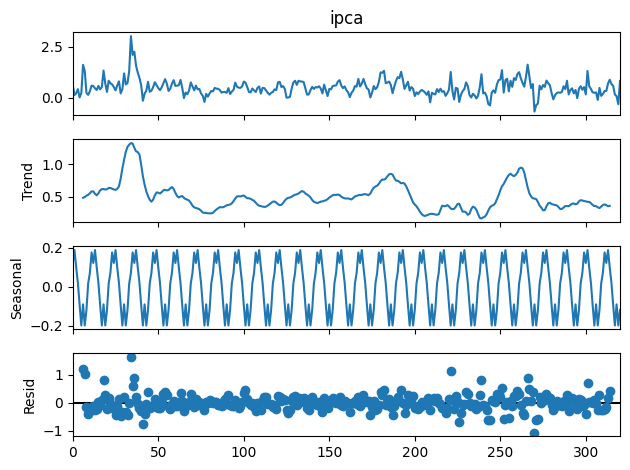

In [12]:
from statsmodels.tsa.seasonal import seasonal_decompose
from matplotlib import pyplot as plt

decompose = seasonal_decompose(ipca, model='additive', period=12)
decompose.plot()
plt.show()


As we can see, the trend has no fixed direction, since as we know, the inflation
rate oscillates constantly. Furthermore, in the seasonality component we can see
that during seasonal periods there is an increase or decrease of 0.2 percentage
points. In the residuals we can observe that they follow a distribution around
the zero line, which makes sense in this case since we are using the additive
method, whose neutral element is 0.

## Examining the distribution

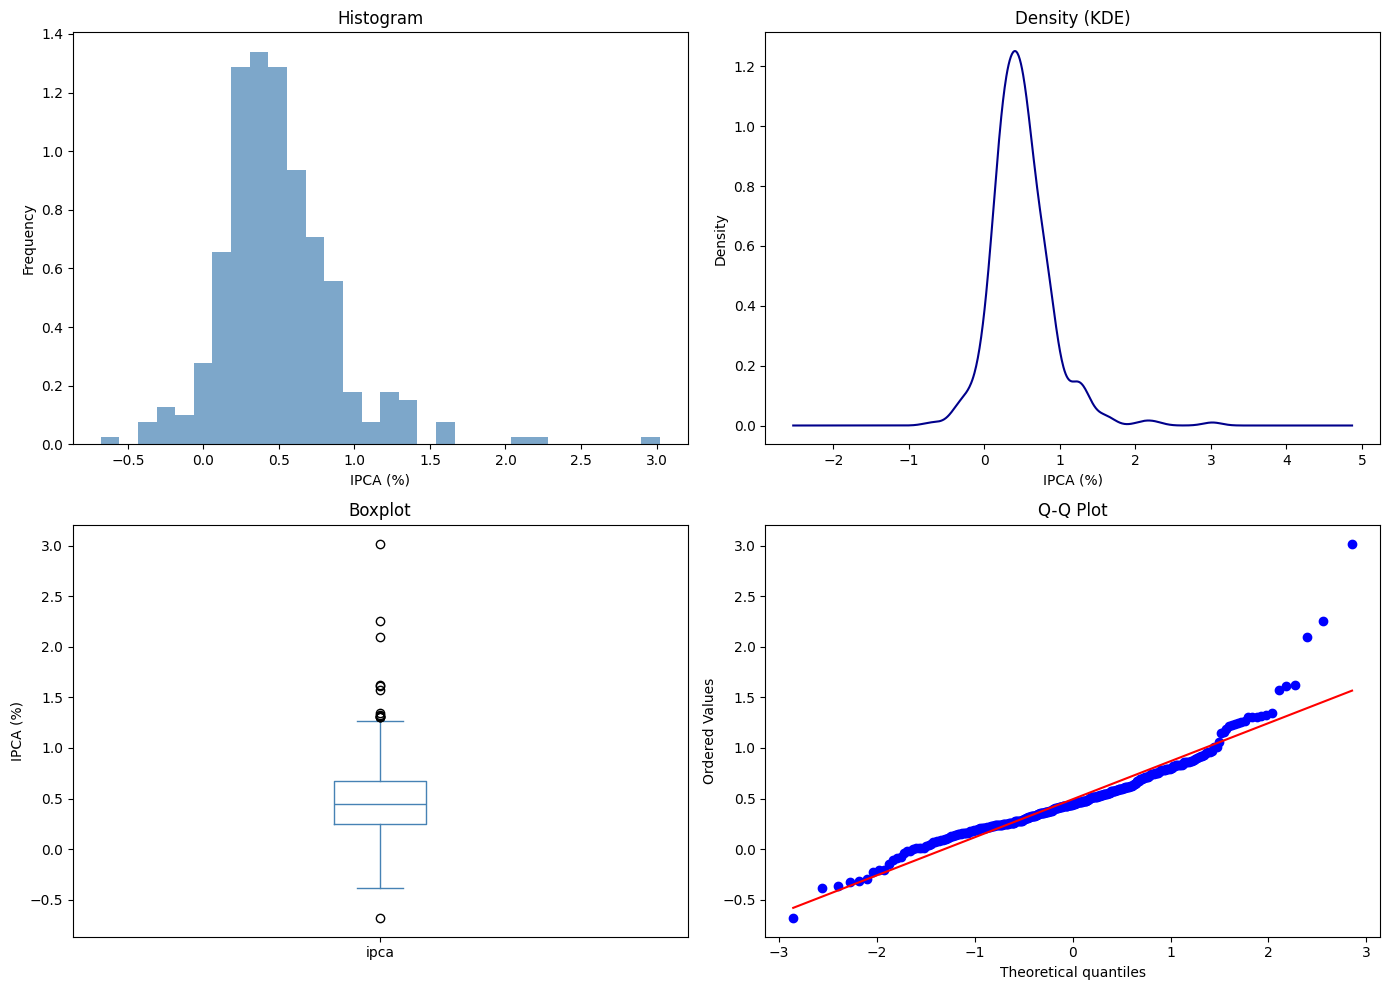

In [13]:
import scipy.stats as stats

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Histograma
ipca.plot(kind='hist', bins=30, density=True, ax=axes[0, 0], color='steelblue', alpha=0.7)
axes[0, 0].set_title('Histogram')
axes[0, 0].set_xlabel('IPCA (%)')

# KDE
ipca.plot(kind='kde', ax=axes[0, 1], color='darkblue')
axes[0, 1].set_title('Density (KDE)')
axes[0, 1].set_xlabel('IPCA (%)')

# Boxplot
ipca.plot(kind='box', ax=axes[1, 0], color='steelblue')
axes[1, 0].set_title('Boxplot')
axes[1, 0].set_ylabel('IPCA (%)')

# Q-Q Plot
stats.probplot(ipca, dist="norm", plot=axes[1, 1])
axes[1, 1].set_title('Q-Q Plot')

plt.tight_layout()
plt.show()

In the histogram and KDE plot, it is possible to notice that the distribution
assumes a positive skewness, with a longer tail to the right. This makes sense
since, in terms of deflation, there is a natural lower boundary close to zero,
however, inflation has no such specific upper limit and can rise depending on the
economic conditions of the country. Furthermore, in the boxplot and Q-Q plot
charts, we notice some outliers which, if cross-referenced with the SGS BCB
database, correspond to three consecutive months in 2002 (November/December) and
2003 (January), in the context of the Brazilian exchange rate crisis of 2002. This
crisis was marked by financial market distrust regarding the possible victory of
Luiz Inácio Lula da Silva in the presidential elections, generating speculative
attacks against the Brazilian real. The scenario was characterized by a sharp rise
in the dollar.

##  ADF - KPSS

In [21]:
import warnings
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tools.sm_exceptions import InterpolationWarning

# Silencia o warning esperado do KPSS (p-valor fora da tabela = não rejeita H0)
warnings.filterwarnings("ignore", category=InterpolationWarning)

def adf(x):
    result = adfuller(x, result_object=True)
    print("ADF TEST")
    print(f"Statistic: {result.statistic:.4f}")
    print(f"P-value:   {result.pvalue:.15f}")
    for key, value in result.critical_values.items():
        print(f"{key}: {value:.3f}")

def kps(x):
    result = kpss(x, regression="c", nlags="auto", result_object=True)
    print("KPSS TEST")
    print(f"Statistic: {result.statistic:.4f}")
    print(f"P-value:   {result.pvalue}")
    for key, value in result.critical_values.items():
        print(f"{key}: {value:.3f}")

adf(ipca)
print()
kps(ipca)

ADF TEST
Statistic: -8.9633
P-value:   0.000000000000008
1%: -3.451
5%: -2.871
10%: -2.572

KPSS TEST
Statistic: 0.2841
P-value:   0.1
10%: 0.347
5%: 0.463
2.5%: 0.574
1%: 0.739


ADF — statistic of -8.75, more negative than the 1% critical value, and p-value
below 0.05. Rejects H0. The series has no unit root.

KPSS — statistic of 0.259, lower than the 10% critical value. P-value of 0.1.
Does not reject H0. The series is also stationary according to KPSS.

The conclusion is that the post-2000 IPCA does not require differencing prior
to modeling.

## ACF

<Figure size 1000x400 with 0 Axes>

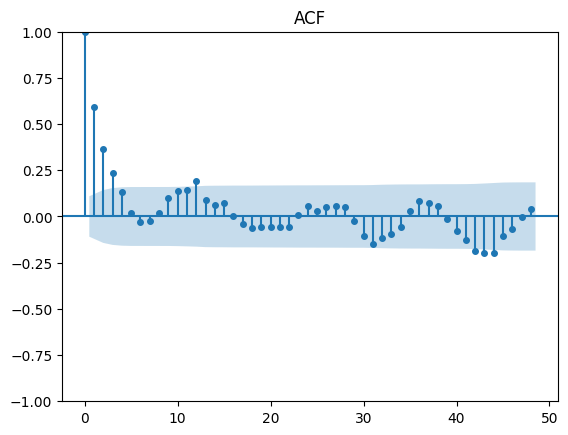

In [18]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

fig = plt.figure(figsize=(10, 4))
auto = plot_acf(ipca, lags=48, markersize=4)
plt.title('ACF')
fig.show()

## PACF

<Figure size 1000x400 with 0 Axes>

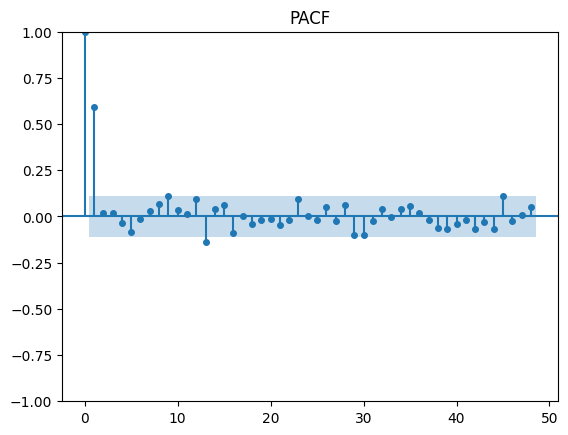

In [19]:

fig = plt.figure(figsize=(10, 4))
auto = plot_pacf(ipca, lags=48, markersize=4)
plt.title('PACF')
fig.show()

## Autocorrelation Analysis (ACF/PACF) — Complementary Diagnostics

The ACF and PACF tests are **not directly used by the Prophet model**, but they serve as complementary diagnostics that inform the modeling choices:

- **Strong short-term autocorrelation (AR(1)):** the ACF shows a high correlation at lag 1, confirming that this month's IPCA is strongly tied to the previous month's. This is a well-known feature of Brazilian inflation and validates the use of models that can capture short-term dynamics.

- **Weak annual seasonality:** no pronounced peaks appear at lags 12, 24, or 36 in the ACF. This suggests that annual seasonality in post-2000 IPCA is modest — which helps explain why Prophet, even with `yearly_seasonality=True`, captures only part of this structure.

- **Stationarity confirmation:** the rapid decay of autocorrelations is consistent with the ADF and KPSS results, reinforcing that the series does not require differencing before modeling.